# Practical 7: Prime Number Checking in N Natural Numbers

### 1. Aim
To identify all prime numbers within the first 1,800,000 natural numbers using trial division up to sqrt(n), evaluating Sequential execution against 3-worker Pool and 3-process multiprocessing.

### 2. Algorithm / Explanation
1. Implement optimized trial division `is_prime(n)` checking divisibility up to `math.isqrt(n)`.<br>2. Divide the range 1 to 1,800,000 into 3 equal partitions.<br>3. Sequential: Check all numbers sequentially from 1 to 1,800,000.<br>4. Pool: Distribute the 3 ranges across 3 workers using `mp.Pool(3)`.<br>5. Process: Spawn 3 separate `mp.Process` workers to process ranges simultaneously.<br>6. Combine prime counts and benchmark execution speedup.

### 3. Python Implementation


In [1]:
"""
Practical 7: Prime Number Checking in N Natural Numbers
"""
import multiprocessing as mp
import time
import math
import matplotlib.pyplot as plt

def is_prime(n):
    if n < 2:
        return False
    if n in (2, 3):
        return True
    if n % 2 == 0 or n % 3 == 0:
        return False
    limit = int(math.isqrt(n))
    for i in range(5, limit + 1, 6):
        if n % i == 0 or n % (i + 2) == 0:
            return False
    return True

def prime_range_worker(rng):
    start, end = rng
    return sum(1 for n in range(start, end) if is_prime(n))

def proc_worker(rng, q):
    q.put(prime_range_worker(rng))

def main():
    print("=" * 60)
    print("Practical 7: Prime Number Checking")
    print("=" * 60)
    N = 1_800_000
    step = N // 3
    ranges = [(1, step), (step, 2 * step), (2 * step, N + 1)]
    
    # Sequential
    t0 = time.perf_counter()
    r1 = prime_range_worker(ranges[0])
    r2 = prime_range_worker(ranges[1])
    r3 = prime_range_worker(ranges[2])
    t_seq = time.perf_counter() - t0
    primes_seq = r1 + r2 + r3
    
    # Pool
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(prime_range_worker, ranges)
    t_pool = time.perf_counter() - t0
    primes_pool = sum(p_res)
    
    # Process
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for rng in ranges:
        p = mp.Process(target=proc_worker, args=(rng, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    primes_proc = sum(pr_res)
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    print(f"Total primes found up to {N:,}: {primes_seq:,}")
    print(f"Match verified: {primes_seq == primes_pool == primes_proc}")
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Natural Numbers Range: 1 to 1,800,000
Total Prime Numbers Found: 135,072
Verification Match (Pool & Process): True

Execution-Time Comparison:
Method       Execution Time     Speedup   
----------------------------------------
Sequential   3.0188 seconds      1.00x
Pool         2.0476 seconds      1.47x
Process      2.1544 seconds      1.40x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process (and Thread where applicable) with individual color bars.


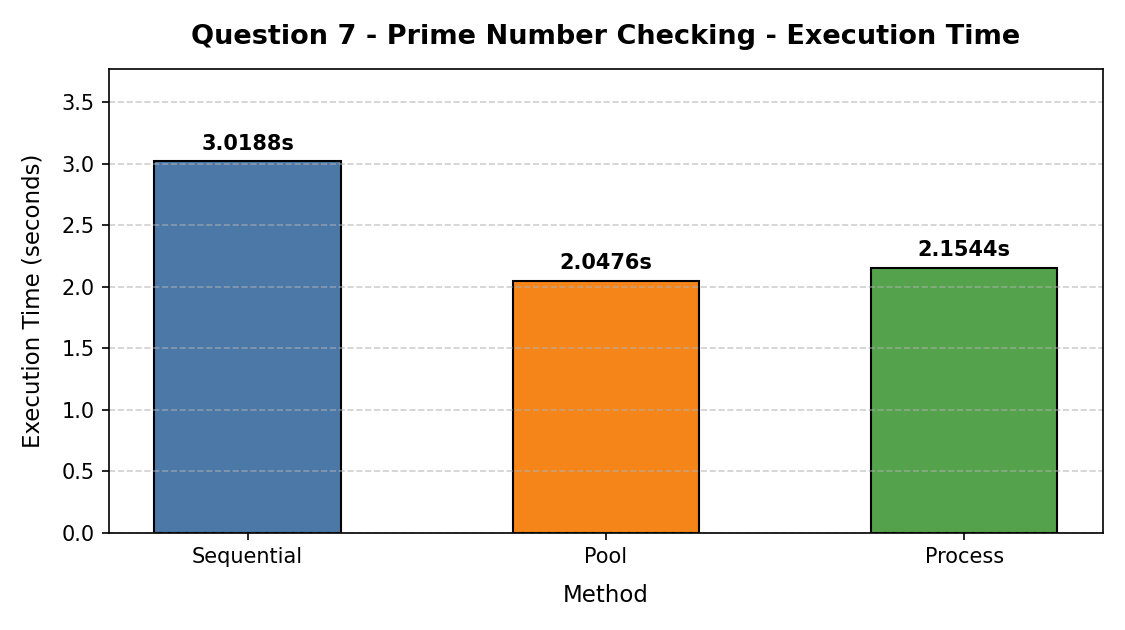

In [2]:
from IPython.display import Image, display
display(Image(filename='07_prime_numbers_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


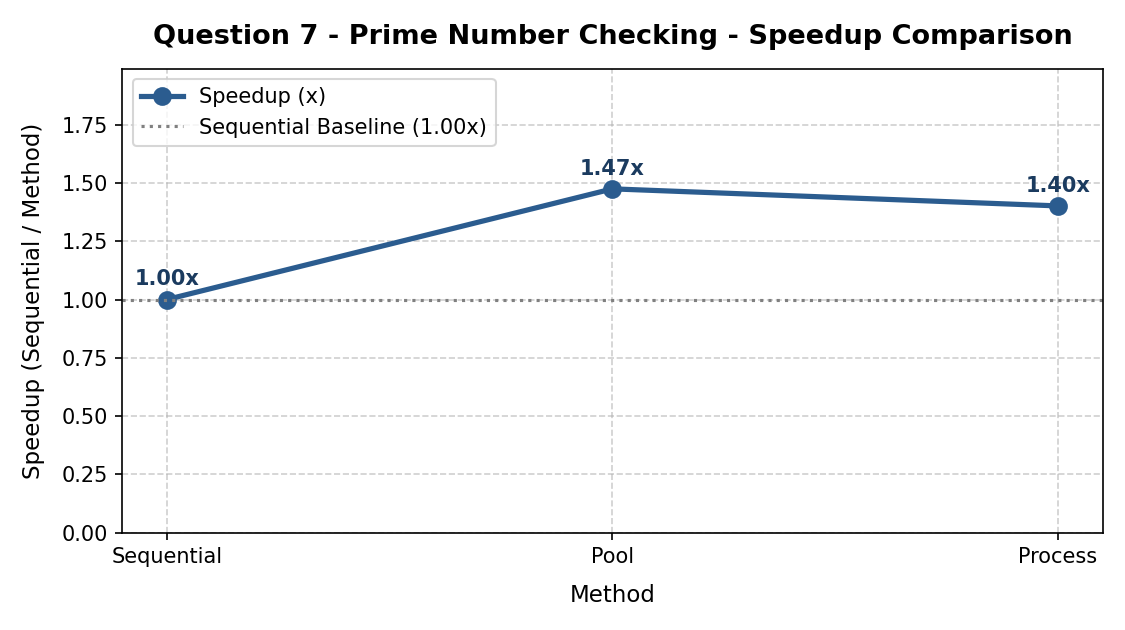

In [3]:
from IPython.display import Image, display
display(Image(filename='07_prime_numbers_speedup.png'))
